# 01 — Exploratory Data Analysis & Data Audit (`DubaiFairValue`)

Audits ingested Dubai Land Department (DLD) residential sales, Ejari rent contracts (or documented fallback), RTA Metro stations, cleaning rules, and Dubai-specific price ordering sanity checks.

In [1]:
import json
import os
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from dfv.config import PATHS, get_data_mode

mode = get_data_mode()
data_dir = PATHS.processed if mode == "processed" else PATHS.sample
print(f"Active data mode: {mode} | Directory: {data_dir}")

Active data mode: processed | Directory: /Users/shahinhamza/.gemini/antigravity/scratch/dubai-fair-value/data/processed


In [2]:
tx = pd.read_parquet(data_dir / "transactions.parquet")
rents = pd.read_parquet(data_dir / "rent_contracts.parquet")
stations = pd.read_parquet(data_dir / "metro_stations.parquet")

print(f"Transactions shape: {tx.shape} | data_source values: {tx['data_source'].unique().tolist()}")
print(f"Date span: {tx['instance_date'].min()} -> {tx['instance_date'].max()}")
print(f"Rent contracts shape: {rents.shape} | data_source: {rents['data_source'].unique().tolist()}")
print(f"Metro stations: {len(stations)} (Route 2020: {int(stations['is_route_2020'].sum())})")

Transactions shape: (490288, 30) | data_source values: ['unofficial_hf_fallback (viewit-ai/full-dubai-pulse)']
Date span: 2015-01-01 -> 2024-08-22
Rent contracts shape: (10000, 17) | data_source: ['synthetic_fallback']
Metro stations: 55 (Route 2020: 5)


In [3]:
# Audit flags and summary statistics
flag_summary = {
    "total_rows": len(tx),
    "flag_outlier": int(tx["flag_outlier"].sum()),
    "flag_non_market": int(tx["flag_non_market"].sum()),
    "flag_duplicate": int(tx["flag_duplicate"].sum()),
}
clean_tx = tx.loc[~tx["flag_outlier"] & ~tx["flag_non_market"] & ~tx["flag_duplicate"]].copy()
print("Flag summary:", flag_summary)
print(f"Unflagged rows used for modeling: {len(clean_tx):,}")

display_cols = ["property_type", "is_offplan"]
summary = (
    clean_tx.groupby(display_cols, as_index=False)
    .agg(
        count=("price_per_sqm", "count"),
        median_ppsqm=("price_per_sqm", "median"),
        median_area_sqm=("area_sqm", "median"),
        median_worth_aed=("actual_worth", "median"),
    )
    .sort_values("count", ascending=False)
)
summary

Flag summary: {'total_rows': 490288, 'flag_outlier': 11918, 'flag_non_market': 1025, 'flag_duplicate': 19362}
Unflagged rows used for modeling: 459,145


,property_type,is_offplan,count,median_ppsqm,median_area_sqm,median_worth_aed
1,Unit,1,225344,16993.573937,74.149704,1234888.0
0,Unit,0,160048,11425.280951,84.539990,1000000.0
2,Villa,0,37797,8880.005500,297.000158,2800000.0
3,Villa,1,35956,9795.056947,190.820242,1900000.0


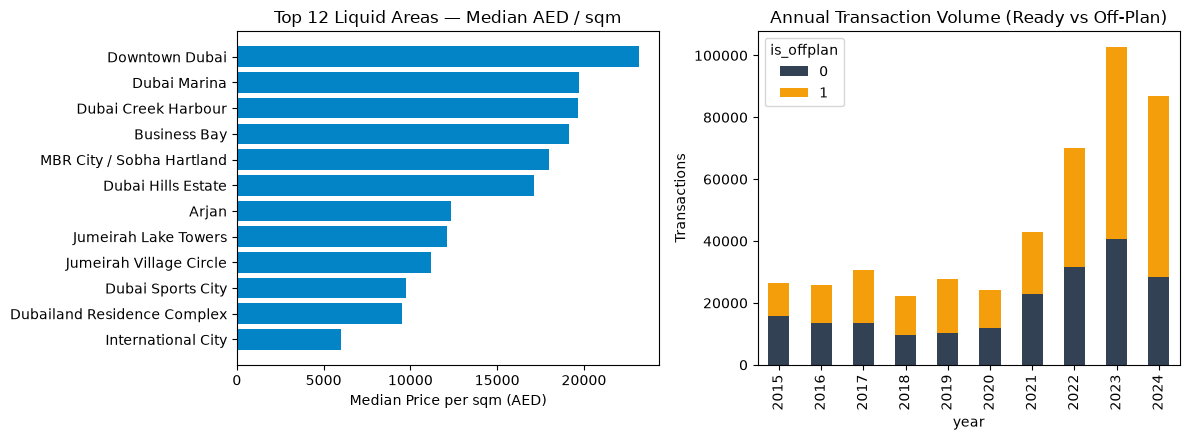

In [4]:
# Top 12 liquid communities median price/sqm and distribution plot
top_areas = (
    clean_tx.groupby("area_name", as_index=False)
    .agg(tx_count=("price_per_sqm", "count"), median_ppsqm=("price_per_sqm", "median"))
    .sort_values("tx_count", ascending=False)
    .head(12)
)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
top_plot = top_areas.sort_values("median_ppsqm")
axes[0].barh(top_plot["area_name"], top_plot["median_ppsqm"], color="#0284C7")
axes[0].set_title("Top 12 Liquid Areas — Median AED / sqm")
axes[0].set_xlabel("Median Price per sqm (AED)")

clean_tx["year"] = pd.to_datetime(clean_tx["instance_date"]).dt.year
yr_counts = clean_tx.groupby(["year", "is_offplan"])["price_per_sqm"].count().unstack(fill_value=0)
yr_counts.plot(kind="bar", stacked=True, ax=axes[1], color=["#334155", "#F59E0B"])
axes[1].set_title("Annual Transaction Volume (Ready vs Off-Plan)")
axes[1].set_ylabel("Transactions")
plt.tight_layout()
plt.show()

**Audit Caveats**: Public DLD fallback data contains area centroids rather than apartment/villa door coordinates, and developer names default to `Unknown` unless `dld_projects-open` is available. Missing Ejari rent contracts and official index series fall back deterministically to documented synthetic generators.